# Comparación en test

Primera evaluación sobre `data/test`. No se reentrena nada.

Dos modelos ya guardados:

- Random Forest (`models/random_forest.joblib`): cinco cumulantes, sin `C21`.
- CNN 1D (`models/cnn.pt`): lote I/Q de forma `(N, 2, 1024)`.

Las predicciones de la CNN son índices. Se pasan a texto con `CLASSES[i]`.
Toda matriz y todo reporte usan `labels=CLASSES`, el orden de la red,
no el orden alfabético de `rf.classes_`.

In [1]:
import csv
import json
import sys
from pathlib import Path

import joblib
import numpy as np
import torch
from sklearn.metrics import classification_report, confusion_matrix

# Path.cwd() es la carpeta desde la que se abrió el notebook.
# Ejemplo: si se abre en notebooks/, cwd es .../coms_proyecto2/notebooks.
# .parents sube: notebooks -> coms_proyecto2 -> home -> ...
current = Path.cwd().resolve()
ROOT = None

for folder in (current,) + tuple(current.parents):
    if (folder / "data" / "train" / "X.npy").is_file():
        ROOT = folder
        break

if ROOT is None:
    raise FileNotFoundError(
        "No se encontro data/train/X.npy subiendo desde {}.".format(current)
    )

# sys.path es la lista de carpetas donde import busca módulos.
# insert(0, ruta) la pone primera. Sin esto, "import src" falla
# si el kernel arrancó dentro de notebooks/.
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.models import ModulationCNN
from src.pre_procesamiento import CLASSES, normalize_iq_batch

TEST_DIR = ROOT / "data" / "test"
N_TEST = 11200

print("Proyecto:", ROOT)
print("Clases:", CLASSES)
assert CLASSES[-1] == "ruido"
assert len(CLASSES) == 7


Proyecto: /home/lcmj2803/coms_proyecto2
Clases: ('BPSK', 'QPSK', '8PSK', '16QAM', '64QAM', '16APSK', 'ruido')


/home/lcmj2803/.local/lib/python3.10/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/home/lcmj2803/.local/lib/python3.10/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.2' currently installed).
  from pandas.core import (


In [2]:
# csv.DictReader usa la primera línea como nombres de columna.
# Entrada (texto): "mod,snr_db\nBPSK,-10.0\n"
# Salida: [{"mod": "BPSK", "snr_db": "-10.0"}]
# Los valores salen como str. float("nan") es nan, no un error.
with (TEST_DIR / "meta.csv").open(
    "r", newline="", encoding="utf-8"
) as file:
    metadata = list(csv.DictReader(file))

y_true = np.array([row["mod"] for row in metadata])
esn0 = np.array([float(row["snr_db"]) for row in metadata])

print("Filas:", len(metadata))
print("Etiquetas:", sorted(set(y_true)))
print("Ruido con Es/N0 nan:", int(np.sum((y_true == "ruido") & ~np.isfinite(esn0))))

assert len(metadata) == N_TEST
assert set(y_true) == set(CLASSES)
assert np.all(np.isfinite(esn0[y_true != "ruido"]))
assert np.all(~np.isfinite(esn0[y_true == "ruido"]))


Filas: 11200
Etiquetas: ['16APSK', '16QAM', '64QAM', '8PSK', 'BPSK', 'QPSK', 'ruido']
Ruido con Es/N0 nan: 1600


In [3]:
# np.load lee un arreglo .npy. allow_pickle=False rechaza objetos Python.
# json.load lee un texto JSON y devuelve dict/list.
# Entrada: '{"columns": ["abs_C20", "C21"]}'
# Salida: {"columns": ["abs_C20", "C21"]}
features = np.load(
    str(TEST_DIR / "features.npy"),
    allow_pickle=False,
)

with (TEST_DIR / "features_info.json").open(
    "r", encoding="utf-8"
) as file:
    info = json.load(file)

columns = info["columns"]

print("Features:", features.shape, features.dtype)
print("Columnas:", columns)

assert features.shape == (N_TEST, 6)
assert features.dtype == np.float32
assert np.all(np.isfinite(features))
assert columns[1] == "C21"
assert len(features) == len(y_true)


Features: (11200, 6) float32
Columnas: ['abs_C20', 'C21', 'abs_C40', 'C42', 'abs_C60', 'C63']


In [4]:
# np.delete(arreglo, indice, axis=1) quita una columna y devuelve copia.
# Entrada: np.delete([[1.0, 9.0, 3.0]], 1, axis=1)
# Salida:  [[1.0, 3.0]]
# El bosque se entrenó sin C21: esa columna queda ~1 tras normalizar.
c21_index = columns.index("C21")
X_rf = np.delete(features, c21_index, axis=1)
rf_names = [name for name in columns if name != "C21"]

print("Columnas del bosque:", rf_names)
print("Forma para el bosque:", X_rf.shape)
assert c21_index == 1
assert "C21" not in rf_names
assert X_rf.shape == (N_TEST, 5)
assert not np.shares_memory(X_rf, features)


Columnas del bosque: ['abs_C20', 'abs_C40', 'C42', 'abs_C60', 'C63']
Forma para el bosque: (11200, 5)


In [5]:
from src.features import extract_features
from src.pipeline import iq_a_complejo

# iq_a_complejo((2, 1024)) junta I y Q en un vector complejo de 1024.
# extract_features(ese vector) devuelve 6 float32, el mismo orden que features.npy.
# Se comprueba una fila de cada extremo: el orden de filas es el de X.npy.
iq = np.load(
    str(TEST_DIR / "X.npy"),
    mmap_mode="r",
    allow_pickle=False,
)

assert iq.shape == (N_TEST, 2, 1024)
assert iq.dtype == np.float32

for indice in (0, N_TEST // 2, N_TEST - 1):
    recalculado = extract_features(iq_a_complejo(iq[indice]))
    np.testing.assert_allclose(
        recalculado,
        features[indice],
        rtol=0.0,
        atol=0.0,
    )
    print(
        "Fila {}: {} coincide. |C20| = {:.4f}".format(
            indice, y_true[indice], float(features[indice, 0])
        )
    )


Fila 0: BPSK coincide. |C20| = 0.0222
Fila 5600: 16QAM coincide. |C20| = 0.0395
Fila 11199: ruido coincide. |C20| = 0.0271


In [6]:
# joblib.load(ruta) reconstruye el objeto guardado con joblib.dump.
# Aquí es un RandomForestClassifier ya entrenado: no se llama a fit.
# classes_ son las etiquetas de texto, en orden alfabético.
# n_features_in_ es cuántas columnas vio el entrenamiento.
# predict(X) con X de forma (n, 5) devuelve n nombres de clase.
import warnings
from sklearn.exceptions import InconsistentVersionWarning

warnings.filterwarnings("ignore", category=InconsistentVersionWarning)

rf = joblib.load(str(ROOT / "models" / "random_forest.joblib"))
y_pred_rf = rf.predict(X_rf)

print("clases del bosque:", list(rf.classes_))
print("columnas de entrada:", rf.n_features_in_)
print("predicción fila 0:", y_pred_rf[0], "| real:", y_true[0])

assert rf.n_features_in_ == X_rf.shape[1]
assert list(rf.classes_) == sorted(CLASSES)
assert list(rf.classes_) != list(CLASSES)
assert y_pred_rf.shape == (N_TEST,)
assert set(y_pred_rf).issubset(set(CLASSES))


clases del bosque: ['16APSK', '16QAM', '64QAM', '8PSK', 'BPSK', 'QPSK', 'ruido']
columnas de entrada: 5
predicción fila 0: ruido | real: BPSK


In [7]:
# torch.load(..., map_location="cpu") lee el archivo en CPU
# aunque se hubiera guardado en GPU.
# weights_only=True acepta tensores y rechaza código ejecutable.
# El archivo es un state_dict: diccionario nombre -> tensor de pesos.
# load_state_dict copia esos tensores dentro de una red nueva.
# eval() deja la red en inferencia (sin dropout ni actualización).
cnn = ModulationCNN(num_classes=len(CLASSES))
estado = torch.load(
    str(ROOT / "models" / "cnn.pt"),
    map_location="cpu",
    weights_only=True,
)
incompatible = cnn.load_state_dict(estado)
cnn.eval()

print("Tensores cargados:", len(estado))
print("Faltan:", incompatible.missing_keys)
print("Sobran:", incompatible.unexpected_keys)

assert len(estado) > 0
assert incompatible.missing_keys == []
assert incompatible.unexpected_keys == []
assert not cnn.training


Tensores cargados: 8
Faltan: []
Sobran: []


In [8]:
# Se predice por lotes para no normalizar las 11200 señales de una vez
# en un solo paso más grande de la cuenta.
# normalize_iq_batch centra I y Q y deja potencia 1. Devuelve float32.
# torch.from_numpy comparte memoria con el arreglo; no copia.
# torch.no_grad() no guarda gradientes: la red no se entrena.
# softmax(puntuaciones, dim=1) las vuelve probabilidades por fila.
#   Entrada:  [[2.0, 0.0]]
#   Salida:   [[0.88, 0.12]]   (suman 1)
# La columna i de ese softmax es la probabilidad de CLASSES[i].
# argmax(dim=1) es el índice de la clase más alta de cada fila.
#   Entrada:  [[0.1, 0.9, 0.0]]
#   Salida:   [1]
# .numpy() pasa el tensor a un arreglo NumPy.
# np.concatenate pega los lotes, uno debajo del otro.
BATCH = 256
indices_cnn = []
probabilidades_cnn = []

with torch.no_grad():
    for start in range(0, N_TEST, BATCH):
        lote = normalize_iq_batch(iq[start:start + BATCH])
        puntuaciones = cnn(torch.from_numpy(lote))
        probabilidades = torch.softmax(puntuaciones, dim=1)
        indices_cnn.append(puntuaciones.argmax(dim=1).numpy())
        probabilidades_cnn.append(probabilidades.numpy())

y_index_cnn = np.concatenate(indices_cnn).astype(np.int64)
prob_cnn = np.concatenate(probabilidades_cnn)
y_pred_cnn = np.array([CLASSES[i] for i in y_index_cnn])

print("Índices CNN, fila 0:", int(y_index_cnn[0]), "->", y_pred_cnn[0])
print("prob_cnn:", prob_cnn.shape, prob_cnn.dtype)
print("Suma de la fila 0:", float(prob_cnn[0].sum()))

assert y_index_cnn.shape == (N_TEST,)
assert y_pred_cnn.shape == (N_TEST,)
assert prob_cnn.shape == (N_TEST, len(CLASSES))
assert set(y_pred_cnn).issubset(set(CLASSES))
assert np.array_equal(
    y_pred_cnn,
    np.asarray(CLASSES)[y_index_cnn],
)
assert np.array_equal(
    y_index_cnn,
    np.argmax(prob_cnn, axis=1),
)
assert np.allclose(prob_cnn.sum(axis=1), 1.0)


Índices CNN, fila 0: 1 -> QPSK
prob_cnn: (11200, 7) float32
Suma de la fila 0: 0.9999999403953552


In [9]:
# predict_proba(X) devuelve P(clase | fila). No se llama a fit.
# La forma es (n_filas, n_clases). La columna j corresponde a
# rf.classes_[j], que está en orden alfabético, no en el de CLASSES.
#
# Indexación con 3 clases. Supón:
#   rf.classes_ = ["8PSK", "BPSK", "QPSK"]
#   una fila     = [ 0.10,   0.70,   0.20 ]
#   CLASSES      = ("BPSK", "QPSK", "8PSK")
# list.index(nombre) busca la posición de ese nombre.
#   "BPSK" -> 1, "QPSK" -> 2, "8PSK" -> 0
#   orden = [1, 2, 0]
# fila[:, orden] toma esas columnas y las deja en el orden pedido:
#   [0.70, 0.20, 0.10]
# La columna 0 pasa a ser BPSK. No se escriben los índices a mano:
# se buscan los siete nombres de CLASSES dentro de rf.classes_.
orden_rf = [list(rf.classes_).index(nombre) for nombre in CLASSES]
prob_rf = rf.predict_proba(X_rf)[:, orden_rf]

print("Orden alfabético:", list(rf.classes_))
print("Columnas tomadas:", orden_rf)
print("prob_rf:", prob_rf.shape, prob_rf.dtype)
print("Suma de la fila 0:", float(prob_rf[0].sum()))

assert orden_rf != list(range(len(CLASSES)))
assert list(np.asarray(rf.classes_)[orden_rf]) == list(CLASSES)
assert prob_rf.shape == (N_TEST, len(CLASSES))
assert np.allclose(prob_rf.sum(axis=1), 1.0)


Orden alfabético: ['16APSK', '16QAM', '64QAM', '8PSK', 'BPSK', 'QPSK', 'ruido']
Columnas tomadas: [4, 5, 3, 1, 2, 0, 6]
prob_rf: (11200, 7) float64
Suma de la fila 0: 0.9999999999999998


In [10]:
# Path.mkdir crea la carpeta. parents=True crea también las que falten
# por encima. exist_ok=True no falla si results/ ya existe.
# np.savez(ruta, nombre=arreglo, ...) guarda varios arreglos en un .npz
# (un zip de archivos .npy). Cada nombre queda como clave.
# Ejemplo:
#   np.savez("p.npz", a=np.array([1, 2]))
#   datos = np.load("p.npz", allow_pickle=False)
#   datos.files          -> ["a"]
#   datos["a"]           -> array([1, 2])
# allow_pickle=False rechaza objetos Python arbitrarios. Los textos de
# y_true se guardan como arreglo de cadenas de NumPy y sí se pueden leer.
RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
ruta_resultados = RESULTS_DIR / "exp4_test.npz"

np.savez(
    ruta_resultados,
    y_true=y_true,
    esn0=esn0,
    y_pred_rf=y_pred_rf,
    y_pred_cnn=y_pred_cnn,
    prob_rf=prob_rf,
    prob_cnn=prob_cnn,
    classes=np.array(CLASSES),
)

cargado = np.load(ruta_resultados, allow_pickle=False)

# Una tupla no acepta un arreglo de índices: CLASSES[np.array([0, 1])]
# lanza TypeError. np.array(CLASSES)[indices] sí devuelve los nombres.
nombres_cnn = np.array(CLASSES)[np.argmax(cargado["prob_cnn"], axis=1)]
nombres_rf = np.array(CLASSES)[np.argmax(cargado["prob_rf"], axis=1)]

exactitud_rf = float(np.mean(cargado["y_true"] == cargado["y_pred_rf"]))
exactitud_cnn = float(np.mean(cargado["y_true"] == cargado["y_pred_cnn"]))
filas_distintas = int(np.count_nonzero(nombres_rf != cargado["y_pred_rf"]))

print("Claves:", cargado.files)
print("Random Forest: {:.2%}".format(exactitud_rf))
print("CNN 1D:        {:.2%}".format(exactitud_cnn))
print(
    "Filas donde argmax(prob_rf) no coincide con y_pred_rf: {}".format(
        filas_distintas
    )
)
print(
    "Desvío máximo de la suma por fila, RF: {:.3e}".format(
        float(np.max(np.abs(cargado["prob_rf"].sum(axis=1) - 1.0)))
    )
)
print(
    "Desvío máximo de la suma por fila, CNN: {:.3e}".format(
        float(np.max(np.abs(cargado["prob_cnn"].sum(axis=1) - 1.0)))
    )
)

assert cargado["prob_cnn"].shape == (N_TEST, len(CLASSES))
assert cargado["prob_rf"].shape == (N_TEST, len(CLASSES))
assert list(cargado["classes"]) == list(CLASSES)
assert "{:.2%}".format(exactitud_rf) == "35.80%"
assert "{:.2%}".format(exactitud_cnn) == "48.05%"
assert np.array_equal(nombres_cnn, cargado["y_pred_cnn"])
assert filas_distintas == 0
assert np.allclose(cargado["prob_rf"].sum(axis=1), 1.0)
assert np.allclose(cargado["prob_cnn"].sum(axis=1), 1.0)

cargado.close()


Claves: ['y_true', 'esn0', 'y_pred_rf', 'y_pred_cnn', 'prob_rf', 'prob_cnn', 'classes']
Random Forest: 35.80%
CNN 1D:        48.05%
Filas donde argmax(prob_rf) no coincide con y_pred_rf: 0
Desvío máximo de la suma por fila, RF: 5.551e-16
Desvío máximo de la suma por fila, CNN: 2.384e-07


In [11]:
def exactitud(y_real, y_pred):
    """Fracción de aciertos, con filas y columnas en el orden de CLASSES.

    confusion_matrix cuenta pares (real, predicha).
    labels fija el orden de filas y columnas. Sin labels, sklearn
    ordena las etiquetas que aparezcan, y el bosque es alfabético.

    Entrada:
        y_real = ["BPSK", "QPSK"]
        y_pred = ["QPSK", "QPSK"]
        labels = ["BPSK", "QPSK"]
    Salida:
        [[0, 1],
         [0, 1]]
    La diagonal son aciertos. exactitud = suma(diagonal) / suma(matriz).
    """
    matriz = confusion_matrix(
        y_real,
        y_pred,
        labels=list(CLASSES),
    )
    total = int(matriz.sum())
    aciertos = int(np.trace(matriz))
    return aciertos / float(total), aciertos, total, matriz


acc_rf, ok_rf, n_rf, cm_rf = exactitud(y_true, y_pred_rf)
acc_cnn, ok_cnn, n_cnn, cm_cnn = exactitud(y_true, y_pred_cnn)

print("Random Forest: {} / {} = {:.2%}".format(ok_rf, n_rf, acc_rf))
print("CNN 1D:        {} / {} = {:.2%}".format(ok_cnn, n_cnn, acc_cnn))

assert n_rf == N_TEST and n_cnn == N_TEST
assert cm_rf.shape == (len(CLASSES), len(CLASSES))
assert cm_cnn.shape == (len(CLASSES), len(CLASSES))
assert list(CLASSES) != sorted(CLASSES)


Random Forest: 4010 / 11200 = 35.80%
CNN 1D:        5382 / 11200 = 48.05%


In [12]:
# classification_report resume precisión, recall y f1 por clase.
# precision: de lo que el modelo llamó "BPSK", cuánto era BPSK.
# recall:    de los BPSK reales, cuántos llamó "BPSK".
# labels=CLASSES obliga el mismo orden en los dos reportes.
# zero_division=0 escribe 0.0 si una clase no recibió predicciones,
# en vez de avisar.
reporte_rf = classification_report(
    y_true,
    y_pred_rf,
    labels=list(CLASSES),
    zero_division=0,
)
reporte_cnn = classification_report(
    y_true,
    y_pred_cnn,
    labels=list(CLASSES),
    zero_division=0,
)

print("Random Forest")
print(reporte_rf)
print("CNN 1D")
print(reporte_cnn)

assert reporte_rf.splitlines()[0].split()[:3] == ["precision", "recall", "f1-score"]
assert "BPSK" in reporte_rf.splitlines()[2]
assert "BPSK" in reporte_cnn.splitlines()[2]


Random Forest
              precision    recall  f1-score   support

        BPSK       0.76      0.65      0.70      1600
        QPSK       0.53      0.26      0.34      1600
        8PSK       0.48      0.26      0.34      1600
       16QAM       0.27      0.15      0.20      1600
       64QAM       0.28      0.15      0.20      1600
      16APSK       0.39      0.26      0.31      1600
       ruido       0.23      0.78      0.36      1600

    accuracy                           0.36     11200
   macro avg       0.42      0.36      0.35     11200
weighted avg       0.42      0.36      0.35     11200

CNN 1D
              precision    recall  f1-score   support

        BPSK       0.57      0.70      0.63      1600
        QPSK       0.49      0.47      0.48      1600
        8PSK       0.58      0.44      0.50      1600
       16QAM       0.42      0.02      0.04      1600
       64QAM       0.35      0.52      0.42      1600
      16APSK       0.52      0.27      0.36      1600
   

In [13]:
# En test hay 16 niveles de Es/N0, de -10 a 20 dB de 2 en 2.
# Cada nivel tiene 600 señales (100 de cada modulación). El ruido
# tiene snr_db nan y no entra en esta curva: se imprime aparte.
# Una señal predicha como "ruido" cuenta como error.
ESN0_LEVELS = np.arange(-10, 22, 2)
acc_rf_esn0 = []
acc_cnn_esn0 = []

print(
    "{:>8} | {:>6} | {:>8} | {:>8}".format(
        "Es/N0", "n", "RF", "CNN"
    )
)

for level in ESN0_LEVELS:
    mask = (y_true != "ruido") & (esn0 == level)
    count = int(np.count_nonzero(mask))
    assert count == 600, (
        "Se esperaban 600 señales a {} dB; hay {}.".format(level, count)
    )

    acc_nivel_rf, _, _, _ = exactitud(y_true[mask], y_pred_rf[mask])
    acc_nivel_cnn, _, _, _ = exactitud(y_true[mask], y_pred_cnn[mask])
    acc_rf_esn0.append(acc_nivel_rf)
    acc_cnn_esn0.append(acc_nivel_cnn)

    print(
        "{:>8} | {:>6} | {:>8.2%} | {:>8.2%}".format(
            int(level), count, acc_nivel_rf, acc_nivel_cnn
        )
    )

acc_rf_esn0 = np.asarray(acc_rf_esn0)
acc_cnn_esn0 = np.asarray(acc_cnn_esn0)

mask_ruido = y_true == "ruido"
acc_ruido_rf, ok_ruido_rf, n_ruido, _ = exactitud(
    y_true[mask_ruido], y_pred_rf[mask_ruido]
)
acc_ruido_cnn, ok_ruido_cnn, _, _ = exactitud(
    y_true[mask_ruido], y_pred_cnn[mask_ruido]
)

print(
    "Ruido (sin Es/N0): RF {}/{} = {:.2%} | CNN {}/{} = {:.2%}".format(
        ok_ruido_rf, n_ruido, acc_ruido_rf,
        ok_ruido_cnn, n_ruido, acc_ruido_cnn,
    )
)

assert n_ruido == 1600
assert acc_rf_esn0.shape == (16,)
assert acc_cnn_esn0.shape == (16,)


   Es/N0 |      n |       RF |      CNN
     -10 |    600 |    4.33% |    4.17%
      -8 |    600 |    3.17% |    6.50%
      -6 |    600 |    5.33% |   11.17%
      -4 |    600 |    7.33% |   14.67%
      -2 |    600 |    8.83% |   18.83%
       0 |    600 |   13.00% |   24.67%
       2 |    600 |   16.17% |   29.00%
       4 |    600 |   20.33% |   38.33%
       6 |    600 |   22.83% |   43.00%
       8 |    600 |   30.50% |   50.67%
      10 |    600 |   36.67% |   57.33%
      12 |    600 |   41.00% |   63.17%
      14 |    600 |   51.00% |   69.33%
      16 |    600 |   62.00% |   70.17%
      18 |    600 |   69.00% |   74.67%
      20 |    600 |   68.17% |   72.83%
Ruido (sin Es/N0): RF 1252/1600 = 78.25% | CNN 1491/1600 = 93.19%


Figura: /home/lcmj2803/coms_proyecto2/figs/comparacion_test/01_exactitud_vs_esn0_test.png


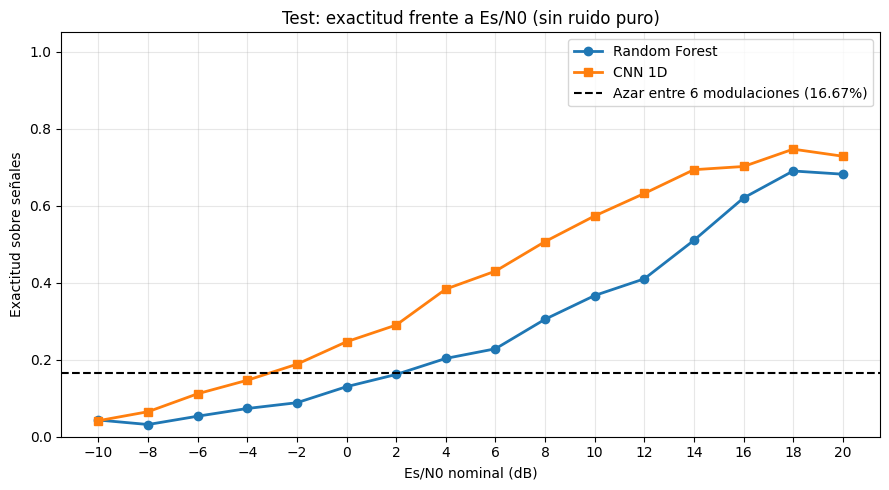

In [14]:
import matplotlib.pyplot as plt

FIG_DIR = ROOT / "figs" / "comparacion_test"
FIG_DIR.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    ESN0_LEVELS,
    acc_rf_esn0,
    marker="o",
    linewidth=2,
    label="Random Forest",
)
ax.plot(
    ESN0_LEVELS,
    acc_cnn_esn0,
    marker="s",
    linewidth=2,
    label="CNN 1D",
)
ax.axhline(
    1.0 / 6.0,
    color="black",
    linestyle="--",
    label="Azar entre 6 modulaciones ({:.2%})".format(1.0 / 6.0),
)

ax.set_xlabel("Es/N0 nominal (dB)")
ax.set_ylabel("Exactitud sobre señales")
ax.set_title("Test: exactitud frente a Es/N0 (sin ruido puro)")
ax.set_xticks(ESN0_LEVELS)
ax.set_ylim(0.0, 1.05)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
fig.savefig(FIG_DIR / "01_exactitud_vs_esn0_test.png", dpi=300, bbox_inches="tight")
fig.savefig(FIG_DIR / "01_exactitud_vs_esn0_test.pdf", bbox_inches="tight")
print("Figura:", FIG_DIR / "01_exactitud_vs_esn0_test.png")
plt.show()

assert (FIG_DIR / "01_exactitud_vs_esn0_test.png").is_file()


Figura: /home/lcmj2803/coms_proyecto2/figs/comparacion_test/02_confusion_porcentajes_test.png


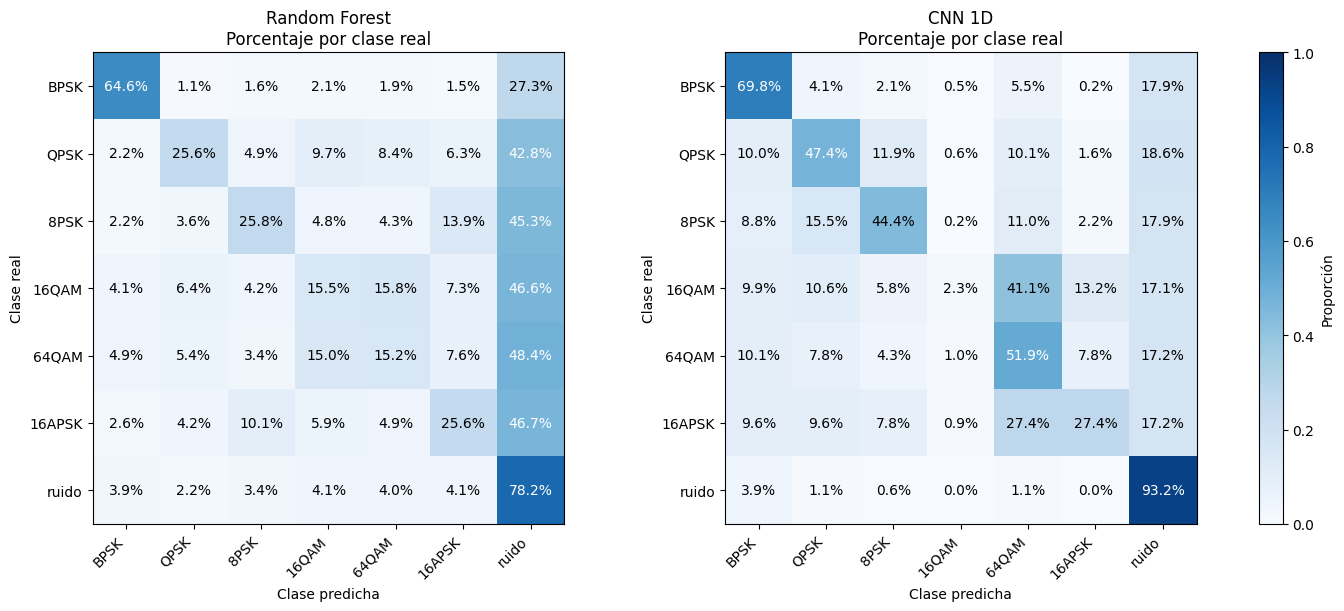

Clase            RF      CNN
BPSK         64.62%   69.75%
QPSK         25.62%   47.38%
8PSK         25.81%   44.44%
16QAM        15.50%    2.31%
64QAM        15.25%   51.94%
16APSK       25.56%   27.38%
ruido        78.25%   93.19%


In [15]:
def porcentajes_por_fila(matriz):
    """Cada fila suma 1: proporción dentro de la clase real.

    Entrada:  [[8, 2],
               [1, 1]]
    Salida:   [[0.8, 0.2],
               [0.5, 0.5]]
    """
    totales = matriz.sum(axis=1, keepdims=True).astype(np.float64)
    assert np.all(totales > 0)
    porcentajes = matriz.astype(np.float64) / totales
    assert np.allclose(porcentajes.sum(axis=1), 1.0)
    return porcentajes


def dibujar_matriz(ax, matriz, titulo):
    imagen = ax.imshow(matriz, cmap="Blues", vmin=0.0, vmax=1.0)
    ticks = np.arange(len(CLASSES))
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.set_xticklabels(CLASSES, rotation=45, ha="right")
    ax.set_yticklabels(CLASSES)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    ax.set_title(titulo)

    umbral = matriz.max() / 2.0
    for fila in range(len(CLASSES)):
        for columna in range(len(CLASSES)):
            ax.text(
                columna,
                fila,
                "{:.1%}".format(matriz[fila, columna]),
                ha="center",
                va="center",
                color="white" if matriz[fila, columna] > umbral else "black",
            )
    return imagen


cm_rf_pct = porcentajes_por_fila(cm_rf)
cm_cnn_pct = porcentajes_por_fila(cm_cnn)

fig, axes = plt.subplots(1, 2, figsize=(14, 6), layout="constrained")
dibujar_matriz(axes[0], cm_rf_pct, "Random Forest\nPorcentaje por clase real")
imagen = dibujar_matriz(axes[1], cm_cnn_pct, "CNN 1D\nPorcentaje por clase real")
fig.colorbar(imagen, ax=axes, fraction=0.03, label="Proporción")
fig.savefig(
    FIG_DIR / "02_confusion_porcentajes_test.png",
    dpi=300,
    bbox_inches="tight",
)
fig.savefig(
    FIG_DIR / "02_confusion_porcentajes_test.pdf",
    bbox_inches="tight",
)
print("Figura:", FIG_DIR / "02_confusion_porcentajes_test.png")
plt.show()

recall_rf = np.diag(cm_rf_pct)
recall_cnn = np.diag(cm_cnn_pct)

print("{:<10} {:>8} {:>8}".format("Clase", "RF", "CNN"))
for nombre, rf_valor, cnn_valor in zip(CLASSES, recall_rf, recall_cnn):
    print("{:<10} {:>8.2%} {:>8.2%}".format(nombre, rf_valor, cnn_valor))

assert np.allclose(cm_rf_pct.sum(axis=1), 1.0)
assert np.allclose(cm_cnn_pct.sum(axis=1), 1.0)
assert (FIG_DIR / "02_confusion_porcentajes_test.png").is_file()


In [16]:
# Lectura de las dos curvas y de los recalls. No cambia ningún modelo.
mejor_rf = int(np.argmax(recall_rf))
peor_rf = int(np.argmin(recall_rf))
mejor_cnn = int(np.argmax(recall_cnn))
peor_cnn = int(np.argmin(recall_cnn))

print(
    "Global: RF {:.2%} | CNN {:.2%}".format(acc_rf, acc_cnn)
)
print(
    "Señales a -10 dB: RF {:.2%} | CNN {:.2%}".format(
        acc_rf_esn0[0], acc_cnn_esn0[0]
    )
)
print(
    "Señales a +20 dB: RF {:.2%} | CNN {:.2%}".format(
        acc_rf_esn0[-1], acc_cnn_esn0[-1]
    )
)
print(
    "Mayor recall RF: {} ({:.2%}). Menor: {} ({:.2%}).".format(
        CLASSES[mejor_rf], recall_rf[mejor_rf],
        CLASSES[peor_rf], recall_rf[peor_rf],
    )
)
print(
    "Mayor recall CNN: {} ({:.2%}). Menor: {} ({:.2%}).".format(
        CLASSES[mejor_cnn], recall_cnn[mejor_cnn],
        CLASSES[peor_cnn], recall_cnn[peor_cnn],
    )
)

mejor_rf_mod = int(np.argmax(recall_rf[:-1]))
peor_rf_mod = int(np.argmin(recall_rf[:-1]))
mejor_cnn_mod = int(np.argmax(recall_cnn[:-1]))
peor_cnn_mod = int(np.argmin(recall_cnn[:-1]))

print(
    "Sin contar ruido, RF: mejor {} ({:.2%}), peor {} ({:.2%}).".format(
        CLASSES[mejor_rf_mod], recall_rf[mejor_rf_mod],
        CLASSES[peor_rf_mod], recall_rf[peor_rf_mod],
    )
)
print(
    "Sin contar ruido, CNN: mejor {} ({:.2%}), peor {} ({:.2%}).".format(
        CLASSES[mejor_cnn_mod], recall_cnn[mejor_cnn_mod],
        CLASSES[peor_cnn_mod], recall_cnn[peor_cnn_mod],
    )
)

niveles_cnn = int(np.sum(acc_cnn_esn0 > acc_rf_esn0))
print(
    "La CNN supera al bosque en {} de {} niveles de Es/N0.".format(
        niveles_cnn, len(ESN0_LEVELS)
    )
)

assert 0.0 <= acc_rf <= 1.0
assert 0.0 <= acc_cnn <= 1.0
assert niveles_cnn <= len(ESN0_LEVELS)


Global: RF 35.80% | CNN 48.05%
Señales a -10 dB: RF 4.33% | CNN 4.17%
Señales a +20 dB: RF 68.17% | CNN 72.83%
Mayor recall RF: ruido (78.25%). Menor: 64QAM (15.25%).
Mayor recall CNN: ruido (93.19%). Menor: 16QAM (2.31%).
Sin contar ruido, RF: mejor BPSK (64.62%), peor 64QAM (15.25%).
Sin contar ruido, CNN: mejor BPSK (69.75%), peor 16QAM (2.31%).
La CNN supera al bosque en 15 de 16 niveles de Es/N0.


In [17]:
import time
import sklearn

# torch.set_num_threads(1) limita a un hilo las cuentas de la red
# (convoluciones, etc.). Sin esto, PyTorch usa varios núcleos.
# rf.n_jobs es cuántos workers usa el bosque en predict.
# El archivo se guardó con n_jobs=2.
#
# Por qué 2 workers castigan una sola observación:
# predict_proba lanza una tarea de joblib por árbol (aquí, 200) y,
# con n_jobs=2, las reparte en 2 hilos que comparten memoria.
# Cada tarea clasifica la fila y luego toma un candado para sumar
# su voto. Una fila de 5 números recorre un árbol en unos pocos
# umbrales. Despertar el segundo hilo, repartir 200 tareas y
# turnarse el candado tarda más que esa cuenta. Con n_jobs=1 las
# mismas 200 tareas corren en el hilo de la llamada, sin pool.
# En un lote grande el recorrido de los árboles sí paga el reparto;
# en una fila, no.
print("n_jobs guardado:", rf.n_jobs)
rf.n_jobs = 1
torch.set_num_threads(1)

modelo_cpu = None
n_procesadores = 0
with open("/proc/cpuinfo", encoding="utf-8") as archivo:
    for linea in archivo:
        if linea.startswith("processor"):
            n_procesadores += 1
        elif linea.startswith("model name") and modelo_cpu is None:
            # "model name\t: Intel..." -> el texto después de los dos puntos.
            modelo_cpu = linea.split(":", 1)[1].strip()

print("CPU:", modelo_cpu)
print("Procesadores lógicos:", n_procesadores)
print("torch:", torch.__version__)
print("sklearn:", sklearn.__version__)
print("hilos torch:", torch.get_num_threads())
print("n_jobs del bosque:", rf.n_jobs)

assert rf.n_jobs == 1
assert torch.get_num_threads() == 1
assert modelo_cpu is not None


n_jobs guardado: 2
CPU: AMD Ryzen 7 5700U with Radeon Graphics
Procesadores lógicos: 16
torch: 2.4.1+cpu
sklearn: 1.7.1
hilos torch: 1
n_jobs del bosque: 1


In [18]:
def rf_una(obs):
    """De una señal (2, 1024) al nombre que predice el bosque."""
    complejo = iq_a_complejo(obs)
    features = extract_features(complejo)
    # np.delete quita C21. reshape(1, -1) hace la fila (1, 5)
    # que predict exige: no acepta un vector suelto de 5.
    fila = np.delete(features, c21_index).reshape(1, -1)
    return rf.predict(fila)[0]


def cnn_una(obs):
    """De una señal (2, 1024) al nombre que predice la CNN."""
    # obs[None] inserta el eje del lote: (2, 1024) -> (1, 2, 1024).
    # Ejemplo: np.zeros((2, 4))[None].shape == (1, 2, 4)
    lote = normalize_iq_batch(obs[None])
    tensor = torch.from_numpy(lote)
    with torch.no_grad():
        puntuaciones = cnn(tensor)
    indice = int(puntuaciones.argmax(dim=1)[0])
    return CLASSES[indice]


def rf_lote(obs_lote):
    """obs_lote tiene forma (B, 2, 1024). Un solo predict para las B filas."""
    filas = []
    for obs in obs_lote:
        features = extract_features(iq_a_complejo(obs))
        filas.append(np.delete(features, c21_index))
    return rf.predict(np.vstack(filas))


def cnn_lote(obs_lote):
    """Normaliza el lote entero y hace un solo forward."""
    lote = normalize_iq_batch(obs_lote)
    tensor = torch.from_numpy(lote)
    with torch.no_grad():
        indices = cnn(tensor).argmax(dim=1).numpy()
    return np.asarray(CLASSES)[indices]


obs0 = np.array(iq[0], dtype=np.float32, copy=True)
nombre_rf = rf_una(obs0)
nombre_cnn = cnn_una(obs0)
print("rf_una fila 0:", nombre_rf, "| guardada:", y_pred_rf[0])
print("cnn_una fila 0:", nombre_cnn, "| guardada:", y_pred_cnn[0])

lote8 = np.array(iq[:8], dtype=np.float32, copy=True)
assert rf_una(obs0) == y_pred_rf[0]
assert cnn_una(obs0) == y_pred_cnn[0]
assert rf_lote(lote8).shape == (8,)
assert cnn_lote(lote8).shape == (8,)


rf_una fila 0: ruido | guardada: ruido
cnn_una fila 0: QPSK | guardada: QPSK


In [19]:
# time.perf_counter() es un reloj monótono, en segundos (float).
# No es la hora del día: no retrocede si cambia el reloj del sistema.
# El tiempo de un tramo es la resta de dos lecturas.
#   t0 = time.perf_counter()
#   trabajo()
#   segundos = time.perf_counter() - t0
#
# default_rng(0) crea un generador con semilla 0. No usa el estado
# global de NumPy. choice(..., replace=False) elige índices distintos.
#   default_rng(0).choice(5, size=3, replace=False)
#   -> 3 enteros distintos entre 0 y 4, siempre los mismos.
rng = np.random.default_rng(0)
indices_tiempo = rng.choice(N_TEST, size=200, replace=False)

pred_rf_crono = []
pred_cnn_crono = []
tiempos_rf = []
tiempos_cnn = []
tiempos_features = []
tiempos_predict = []

for k, indice in enumerate(indices_tiempo):
    obs = np.array(iq[indice], dtype=np.float32, copy=True)

    t0 = time.perf_counter()
    pred_rf_crono.append(rf_una(obs))
    dt_rf = time.perf_counter() - t0

    t0 = time.perf_counter()
    pred_cnn_crono.append(cnn_una(obs))
    dt_cnn = time.perf_counter() - t0

    # El desglose del bosque va aparte, sobre la misma observación.
    # iq_a_complejo entra en extract_features: sin eso no hay cumulantes.
    # Quitar C21 y el reshape entran en predict: sin eso predict no corre.
    t0 = time.perf_counter()
    features = extract_features(iq_a_complejo(obs))
    dt_features = time.perf_counter() - t0

    t0 = time.perf_counter()
    fila = np.delete(features, c21_index).reshape(1, -1)
    rf.predict(fila)
    dt_predict = time.perf_counter() - t0

    if k < 5:
        continue

    tiempos_rf.append(dt_rf)
    tiempos_cnn.append(dt_cnn)
    tiempos_features.append(dt_features)
    tiempos_predict.append(dt_predict)

pred_rf_crono = np.asarray(pred_rf_crono)
pred_cnn_crono = np.asarray(pred_cnn_crono)

print("Índices:", indices_tiempo.shape)
print("Mediciones una a una:", len(tiempos_rf))
print(
    "RF media {:.3f} ms | CNN media {:.3f} ms".format(
        float(np.mean(tiempos_rf) * 1000.0),
        float(np.mean(tiempos_cnn) * 1000.0),
    )
)

assert len(indices_tiempo) == 200
assert len(set(indices_tiempo)) == 200
assert len(tiempos_rf) == 195
assert len(tiempos_cnn) == 195
assert len(tiempos_features) == 195
assert len(tiempos_predict) == 195
assert np.array_equal(pred_rf_crono, y_pred_rf[indices_tiempo])
assert np.array_equal(pred_cnn_crono, y_pred_cnn[indices_tiempo])


Índices: (200,)
Mediciones una a una: 195
RF media 6.871 ms | CNN media 0.693 ms


In [20]:
# Mismo lote de 256 en las 100 repeticiones: el dato no cambia,
# así que la variación es el tiempo, no la señal.
# 5 pasadas previas no se guardan. Cada tiempo guardado ya está
# dividido por 256: es el tiempo por observación dentro del lote.
indices_lote = np.arange(256)
obs_lote = np.array(iq[indices_lote], dtype=np.float32, copy=True)

for _ in range(5):
    rf_lote(obs_lote)
    cnn_lote(obs_lote)

tiempos_rf_lote = []
tiempos_cnn_lote = []
tiempos_features_lote = []
tiempos_predict_lote = []

for _ in range(100):
    t0 = time.perf_counter()
    rf_lote(obs_lote)
    tiempos_rf_lote.append((time.perf_counter() - t0) / 256.0)

    t0 = time.perf_counter()
    cnn_lote(obs_lote)
    tiempos_cnn_lote.append((time.perf_counter() - t0) / 256.0)

    t0 = time.perf_counter()
    filas = []
    for obs in obs_lote:
        features = extract_features(iq_a_complejo(obs))
        filas.append(np.delete(features, c21_index))
    X_lote = np.vstack(filas)
    dt_features = time.perf_counter() - t0

    t0 = time.perf_counter()
    rf.predict(X_lote)
    dt_predict = time.perf_counter() - t0

    tiempos_features_lote.append(dt_features / 256.0)
    tiempos_predict_lote.append(dt_predict / 256.0)

print("Mediciones por lote:", len(tiempos_rf_lote))
print(
    "Por observación, RF {:.3f} ms | CNN {:.3f} ms".format(
        float(np.mean(tiempos_rf_lote) * 1000.0),
        float(np.mean(tiempos_cnn_lote) * 1000.0),
    )
)

assert obs_lote.shape == (256, 2, 1024)
assert len(tiempos_rf_lote) == 100
assert len(tiempos_cnn_lote) == 100
assert len(tiempos_features_lote) == 100
assert len(tiempos_predict_lote) == 100


Mediciones por lote: 100
Por observación, RF 0.252 ms | CNN 0.215 ms


In [21]:
def resumen_ms(segundos):
    """Media, mediana y percentil 95, en milisegundos.

    np.percentile(valores, 95) es el punto bajo el cual cae el 95 %
    de las mediciones.
    Ejemplo: np.percentile([10, 20, 30, 40], 50) -> 25.0
    (la mediana de esos cuatro números).
    """
    ms = np.asarray(segundos, dtype=np.float64) * 1000.0
    return {
        "n": int(ms.size),
        "media_ms": float(np.mean(ms)),
        "mediana_ms": float(np.median(ms)),
        "p95_ms": float(np.percentile(ms, 95)),
    }


filas_tabla = [
    {"modelo": "Random Forest", "modo": "una a una", **resumen_ms(tiempos_rf)},
    {"modelo": "CNN 1D", "modo": "una a una", **resumen_ms(tiempos_cnn)},
    {"modelo": "Random Forest", "modo": "por lote", **resumen_ms(tiempos_rf_lote)},
    {"modelo": "CNN 1D", "modo": "por lote", **resumen_ms(tiempos_cnn_lote)},
]

print(
    "{:<16} {:<12} {:>6} {:>10} {:>10} {:>10}".format(
        "Modelo", "Modo", "n", "media", "mediana", "p95"
    )
)
print(
    "{:<16} {:<12} {:>6} {:>10} {:>10} {:>10}".format(
        "", "", "", "(ms)", "(ms)", "(ms)"
    )
)
for fila in filas_tabla:
    print(
        "{:<16} {:<12} {:>6} {:>10.3f} {:>10.3f} {:>10.3f}".format(
            fila["modelo"],
            fila["modo"],
            fila["n"],
            fila["media_ms"],
            fila["mediana_ms"],
            fila["p95_ms"],
        )
    )

partes_rf = {
    "una a una": {
        "extract_features": resumen_ms(tiempos_features),
        "predict": resumen_ms(tiempos_predict),
    },
    "por lote": {
        "extract_features": resumen_ms(tiempos_features_lote),
        "predict": resumen_ms(tiempos_predict_lote),
    },
}

print()
print("Random Forest, tiempo por observación repartido")
for modo, partes in partes_rf.items():
    for nombre, cifras in partes.items():
        print(
            "  {:<12} {:<18} media {:7.3f}  mediana {:7.3f}  p95 {:7.3f} ms".format(
                modo,
                nombre,
                cifras["media_ms"],
                cifras["mediana_ms"],
                cifras["p95_ms"],
            )
        )

tabla = {
    "cpu": modelo_cpu,
    "procesadores_logicos": n_procesadores,
    "torch": torch.__version__,
    "sklearn": sklearn.__version__,
    "torch_threads": int(torch.get_num_threads()),
    "rf_n_jobs": int(rf.n_jobs),
    "filas": filas_tabla,
    "rf_partes_ms": partes_rf,
}

RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
ruta_tiempos = RESULTS_DIR / "exp4_tiempos.json"
with ruta_tiempos.open("w", encoding="utf-8") as archivo:
    json.dump(tabla, archivo, indent=2, ensure_ascii=False)
    archivo.write("\n")

print()
print("Tabla:", ruta_tiempos)

for fila in filas_tabla:
    assert fila["n"] >= 100
assert tabla["torch_threads"] == 1
assert tabla["rf_n_jobs"] == 1
assert ruta_tiempos.is_file()


Modelo           Modo              n      media    mediana        p95
                                           (ms)       (ms)       (ms)
Random Forest    una a una       195      6.871      6.793      7.366
CNN 1D           una a una       195      0.693      0.672      0.844
Random Forest    por lote        100      0.252      0.248      0.266
CNN 1D           por lote        100      0.215      0.208      0.282

Random Forest, tiempo por observación repartido
  una a una    extract_features   media   0.260  mediana   0.254  p95   0.302 ms
  una a una    predict            media   6.665  mediana   6.614  p95   7.014 ms
  por lote     extract_features   media   0.179  mediana   0.176  p95   0.186 ms
  por lote     predict            media   0.074  mediana   0.073  p95   0.078 ms

Tabla: /home/lcmj2803/coms_proyecto2/results/exp4_tiempos.json
